# Steam Analyzer

This project aims to analyze trends in Steams discount strategy and predict price on games in the future based on it.

[Dataset](https://www.kaggle.com/datasets/benjaminlundkvist/steam-sales-historical-dataset)


# Imports

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

# Data preparation

In [38]:
df = pd.read_csv("data/steam_prices_reviews.csv", parse_dates=["month", "release_date"])

df = df[df["base_price"] > 0]  # remove division by zero
df = df[df["lowest_price"] > 0]  # remove zero or negative prices
df = df[df["lowest_price"] <= df["base_price"]]  # remove negative discounts

# Discount percentage
df["discount_percent"] = (1 - df["lowest_price"] / df["base_price"]) * 100

# Days since release
df["days_since_release"] = (df["month"] - df["release_date"]).dt.days

# Review ratios
df["positive_ratio"] = df["positive"] / df["total_reviews"]
df["negative_ratio"] = df["negative"] / df["total_reviews"]

# Convert review_change_percent from string to numeric
df["review_change_percent"] = (
    df["review_change_percent"]
    .str.replace("-", "0")
    .str.replace("%", "", regex=False)
    .astype(float)
)

# Monthly averages
monthly = df.groupby("month").agg(
    avg_discount=("discount_percent", "mean"),
    avg_days_on_sale=("days_on_sale", "mean"),
    avg_review_change=("review_change_percent", "mean"),
    avg_positive_ratio=("positive_ratio", "mean"),
).reset_index()

monthly.head()

,month,avg_discount,avg_days_on_sale,avg_review_change,avg_positive_ratio
0,2023-11-01,54.120446,9.709091,0.306591,0.865255
1,2023-12-01,55.724852,11.188341,0.170493,0.864467
2,2024-01-01,54.823126,5.070485,0.239824,0.863837
3,2024-02-01,35.528540,3.097778,0.323511,0.865745
4,2024-03-01,53.252675,7.811159,0.560343,0.860828


# Data Visualisation

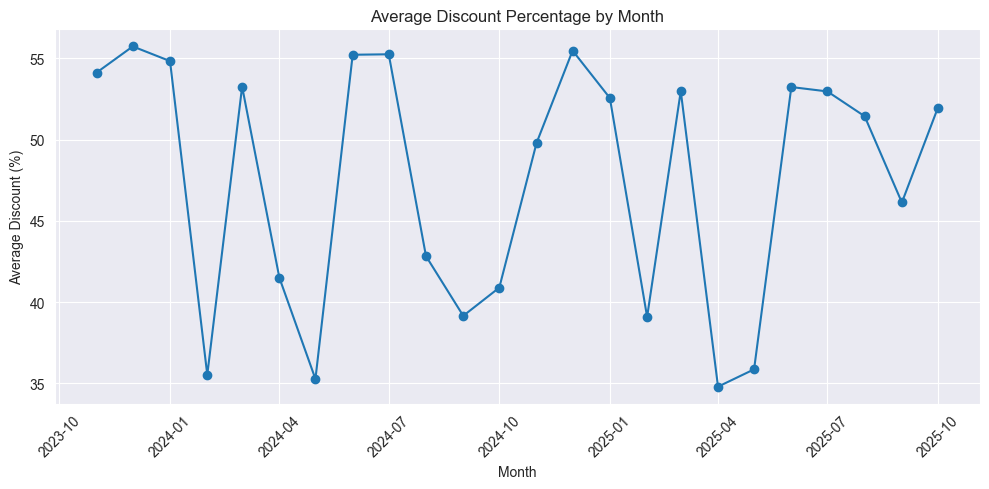

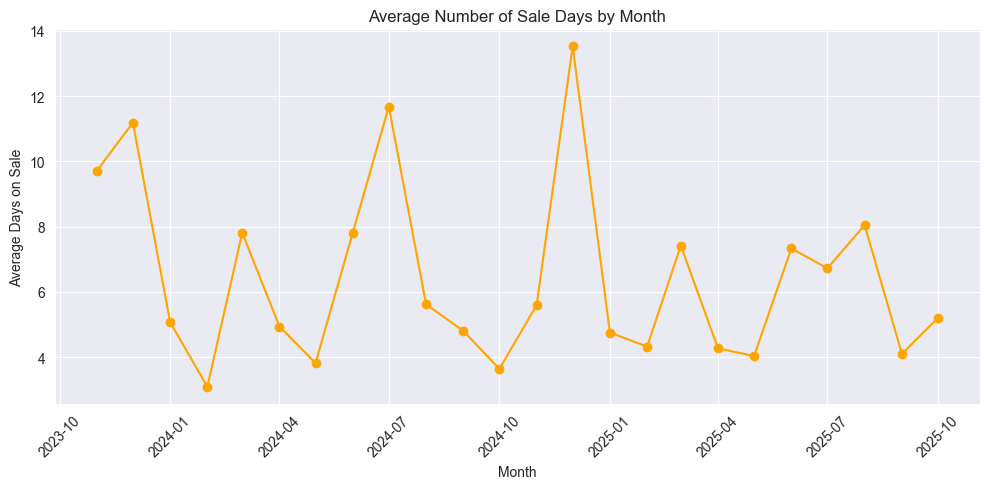

In [39]:
# --- Plot 1: Average discount percentage per month ---
plt.figure(figsize=(10, 5))
plt.plot(monthly["month"], monthly["avg_discount"], marker="o")
plt.title("Average Discount Percentage by Month")
plt.xlabel("Month")
plt.ylabel("Average Discount (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Plot 2: Average number of sale days per month ---
plt.figure(figsize=(10, 5))
plt.plot(monthly["month"], monthly["avg_days_on_sale"], marker="o", color="orange")
plt.title("Average Number of Sale Days by Month")
plt.xlabel("Month")
plt.ylabel("Average Days on Sale")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


The two graphs show a clear positive correlation — months with higher average discounts also tend to have more sale days.
This suggests that major seasonal sales drive both deeper and longer discounts across the platform.

According to these graphs, highest discounts are mostly common in times of major sales,
For example winter 2023-2024 and early autumn 2024 have discounts up to 55%. Its the same for summer 2024 and winter 2024-2025.


The graph also shows, that summer sale 2025 was somewhat short, compared to other years. That suggests, that future user recommendations better include timeperiod instead of just season

Also, October 2025 seems to have low amount of days per sale, however discount reaches over 50%, which is strange.

This anomaly in October 2025 is likely explained by short but major promotions — for example, Space Marine 2 (-50%), Darktide (-60%), and Hunt: Showdown (-60%) all had discounts between late September and early October. These brief yet high-impact sales caused a spike in average discount percentage despite the low number of sale days.

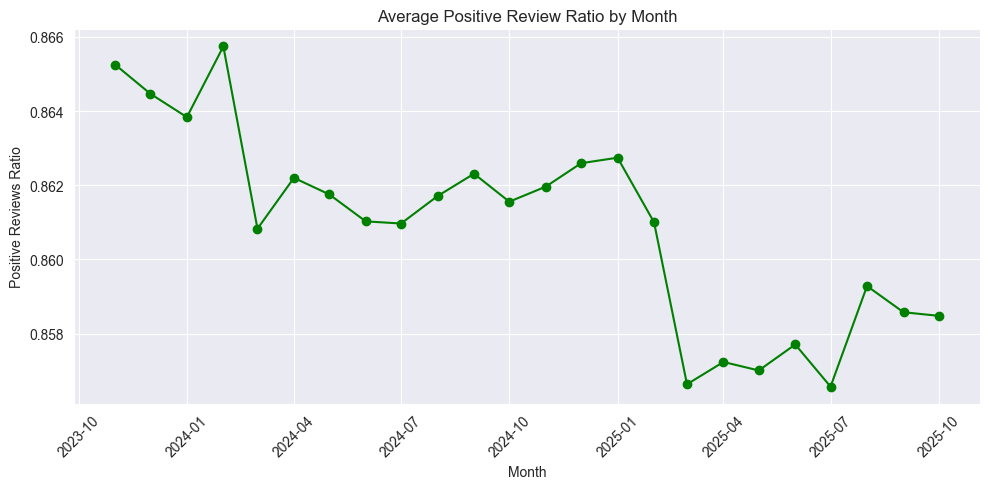

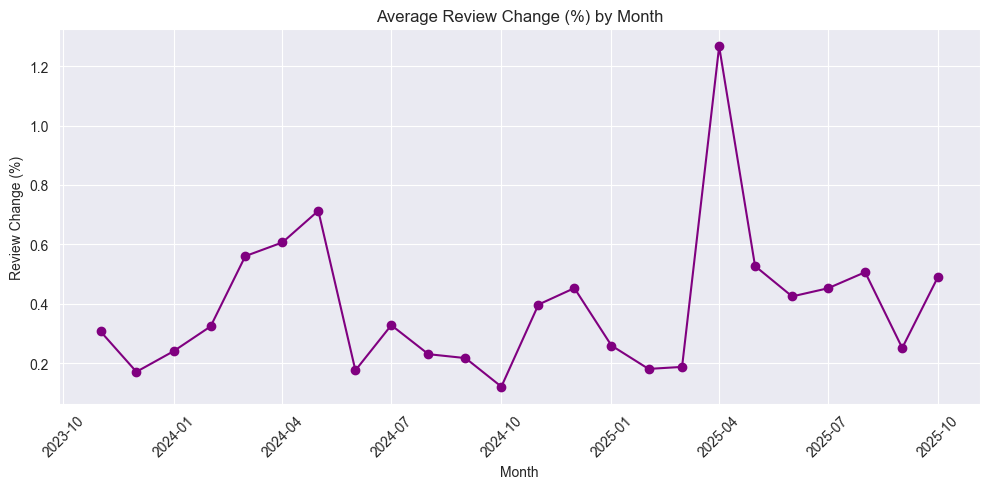

In [40]:
# --- Plot 3: Average positive ratio over time ---
plt.figure(figsize=(10, 5))
plt.plot(monthly["month"], monthly["avg_positive_ratio"], marker="o", color="green")
plt.title("Average Positive Review Ratio by Month")
plt.xlabel("Month")
plt.ylabel("Positive Reviews Ratio")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Plot 4: Review change percentage ---
plt.figure(figsize=(10, 5))
plt.plot(monthly["month"], monthly["avg_review_change"], marker="o", color="purple")
plt.title("Average Review Change (%) by Month")
plt.xlabel("Month")
plt.ylabel("Review Change (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Season sales heatmap

Due to lack of full information regarding 2023 and 2025, comparison of all three of them is not possible, but its possible to compare those years with 2024

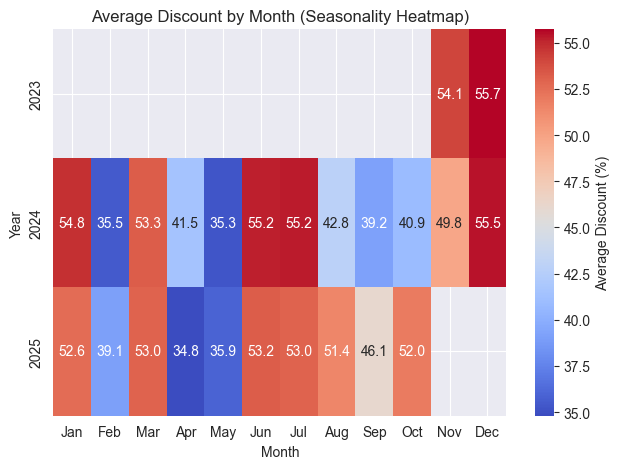

In [41]:
pivot = (
    df.assign(
        year=df['month'].dt.year,
        month_name=df['month'].dt.strftime('%b')
    )
    .groupby(['year', 'month_name'])['discount_percent']
    .mean()
    .unstack()
    .reindex(columns=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
)

sns.heatmap(pivot, cmap="coolwarm", annot=True, fmt=".1f", cbar_kws={'label': 'Average Discount (%)'})
plt.title("Average Discount by Month (Seasonality Heatmap)")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()


its clearly seen: mostly discounts are the same, with small errors up to 3.5 procents. However, late summer and early autumn sales in 2025 (and 2023 in case of october) are 10% higher compared to 2024

However, april 2024 is 6% higher than april 2025. It may add some noise

# Distribution of discounts

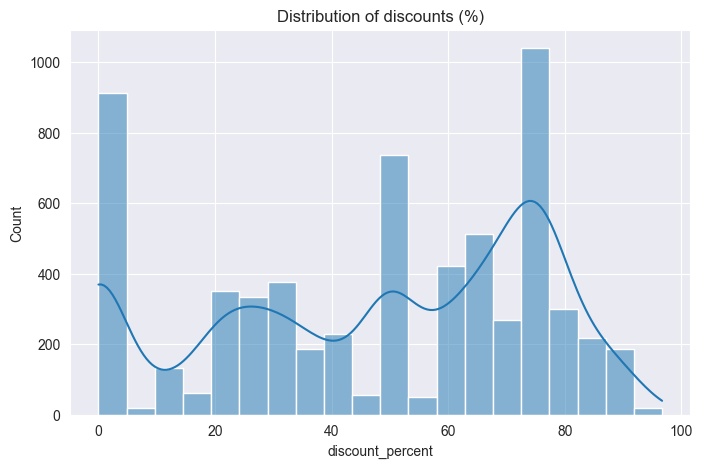

In [42]:
plt.figure(figsize=(8,5))
sns.histplot(df['discount_percent'], bins=20, kde=True)
plt.title("Distribution of discounts (%)")
plt.show()

Most games receive moderate to high discounts, especially around 50–80%. The data confirms that heavy discounts are quite common, possibly due to regular store-wide sales or frequent price adjustments.

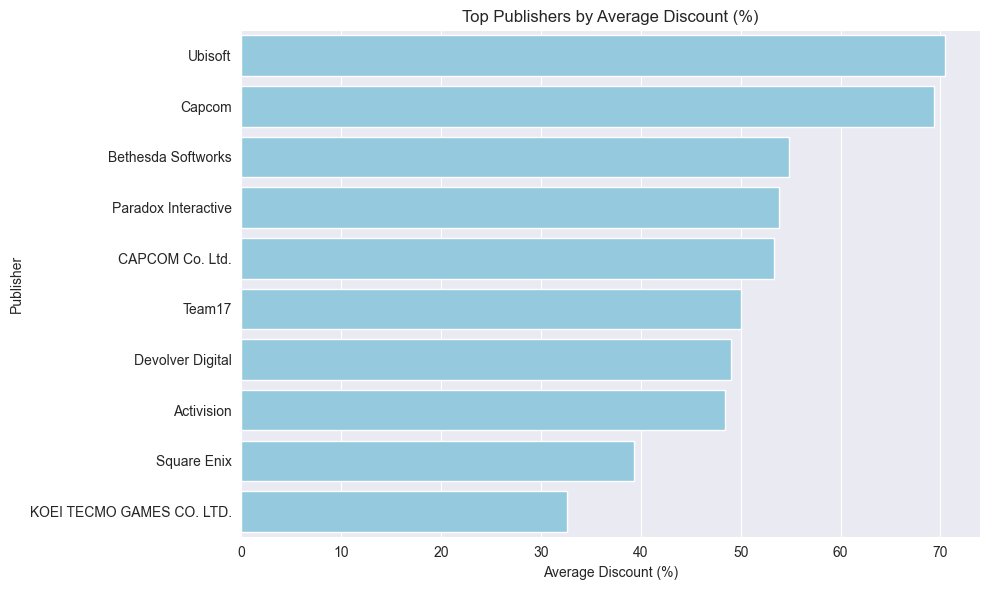

In [43]:
top_publishers = df["publisher"].value_counts().head(10).index
publisher_stats = (
    df[df["publisher"].isin(top_publishers)]
    .groupby("publisher")
    .agg(
        avg_discount=("discount_percent", "mean"),
        avg_positive_ratio=("positive_ratio", "mean"),
        avg_price=("base_price", "mean")
    )
    .sort_values("avg_discount", ascending=False)
)

plt.figure(figsize=(10,6))
sns.barplot(y=publisher_stats.index, x=publisher_stats["avg_discount"], color="skyblue")
plt.title("Top Publishers by Average Discount (%)")
plt.xlabel("Average Discount (%)")
plt.ylabel("Publisher")
plt.tight_layout()
plt.show()

# Heatmap

Going to build a heatmap to search for correlations

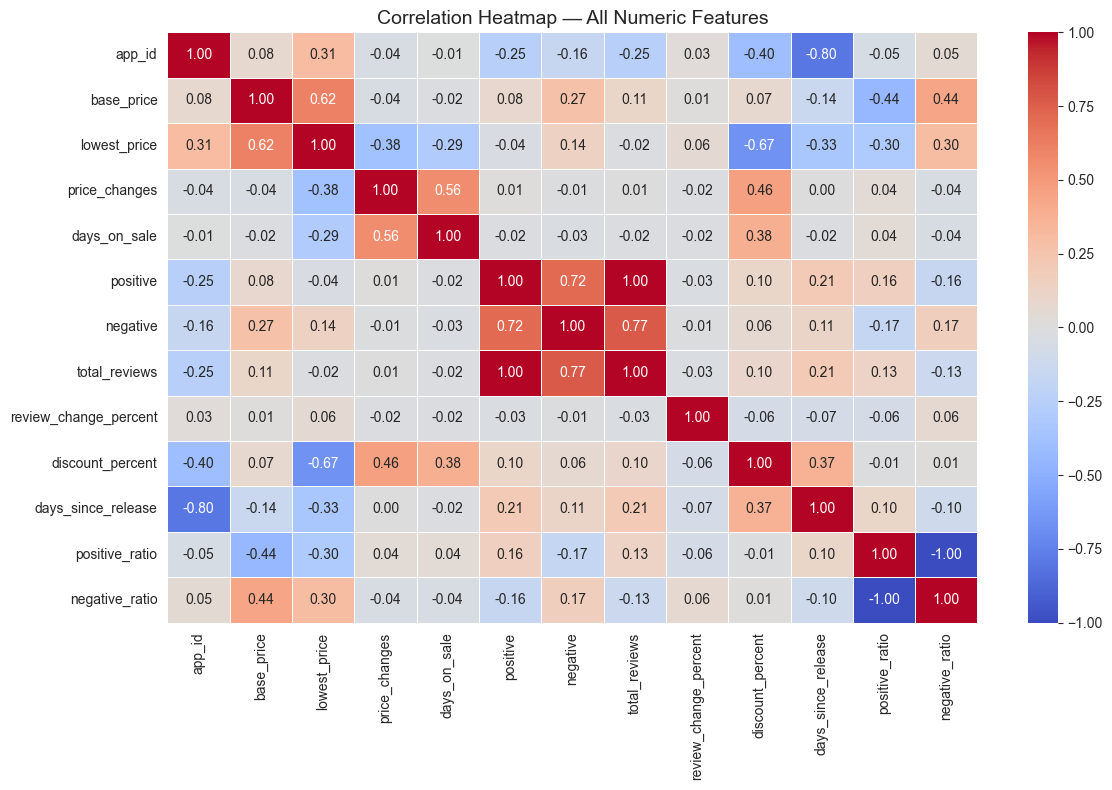

In [44]:
numeric_df = df.select_dtypes(include=["number"])

corr = numeric_df.corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap — All Numeric Features", fontsize=14)
plt.tight_layout()
plt.show()


The most important features for discount percent are
- days since release (0.35)
- days on sale (0.40)
- price changes (0.44)
- lowest price (-0.65) (since its a part of discount percent we will not use it for predictions)

Even though reviews barely correlate with discount percent (since this type of heatmap shows only linear correlations), they are still important features for prediction.

# Building a model
I will use a random forest regressor to predict discount percent.

data cleaning and preparation

In [45]:
# drop weird or missing values
df = df.dropna(subset=[
    'app_id', 'month', 'base_price', 'lowest_price', 'discount_percent',
    'days_since_release', 'days_on_sale', 'price_changes', 'positive_ratio',
    'negative_ratio', 'total_reviews', 'review_change_percent', 'publisher'
])

# make review_change_percent numeric
df["review_change_percent"] = (
    df["review_change_percent"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .str.replace("+", "", regex=False)
    .str.replace("-", "0", regex=False)
    .astype(float)
)

# convert month to datetime if it's not
if not pd.api.types.is_datetime64_any_dtype(df["month"]):
    df["month"] = pd.to_datetime(df["month"], errors="coerce")

# just for model convenience
df["month_num"] = df["month"].dt.month

encoding

In [46]:
df['publisher'] = df['publisher'].astype('category').cat.codes

df = df.drop_duplicates().reset_index(drop=True)

time-based split per game

In [47]:
# split train/test by time for each game
train_idx, test_idx = [], []

for game_id, group in df.groupby("app_id"):
    group = group.sort_values("month")

    # 80% older months go to train, rest to test
    split_point = int(len(group) * 0.8)
    train_idx.extend(group.index[:split_point])
    test_idx.extend(group.index[split_point:])

train_df = df.loc[train_idx]
test_df = df.loc[test_idx]

print(f"Train size: {len(train_df)} | Test size: {len(test_df)}")


Train size: 5032 | Test size: 1369


build features

In [48]:
features = [
    'days_since_release',
    'days_on_sale',
    'price_changes',
    'positive_ratio',
    'negative_ratio',
    'total_reviews',
    'base_price',
    'review_change_percent',
    'month_num'
] + ['publisher']

X_train = train_df[features]
y_train = train_df['discount_percent']

X_test = test_df[features]
y_test = test_df['discount_percent']

print("num of features:", len(features))


num of features: 10


sanity check

In [49]:
# just to make sure split really by time
print("train range:", train_df["month"].min(), "→", train_df["month"].max())
print("test range:", test_df["month"].min(), "→", test_df["month"].max())


train range: 2023-11-01 00:00:00 → 2025-09-01 00:00:00
test range: 2024-07-01 00:00:00 → 2025-10-01 00:00:00


In [50]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# random forest time
model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# predictions
y_pred = model.predict(X_test)

# quick check
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"R²: {r2:.3f}")


MAE: 6.54
R²: 0.836


feature importance

In [51]:
# check which features matter most
imp = pd.Series(model.feature_importances_, index=X_train.columns)
imp = imp.sort_values(ascending=False)

print("\nTop 10 features:")
print(imp.head(10))


Top 10 features:
days_on_sale             0.516488
days_since_release       0.328525
publisher                0.045201
total_reviews            0.034275
positive_ratio           0.024780
negative_ratio           0.023513
base_price               0.019541
review_change_percent    0.004754
month_num                0.001653
price_changes            0.001268
dtype: float64


visualize predictions

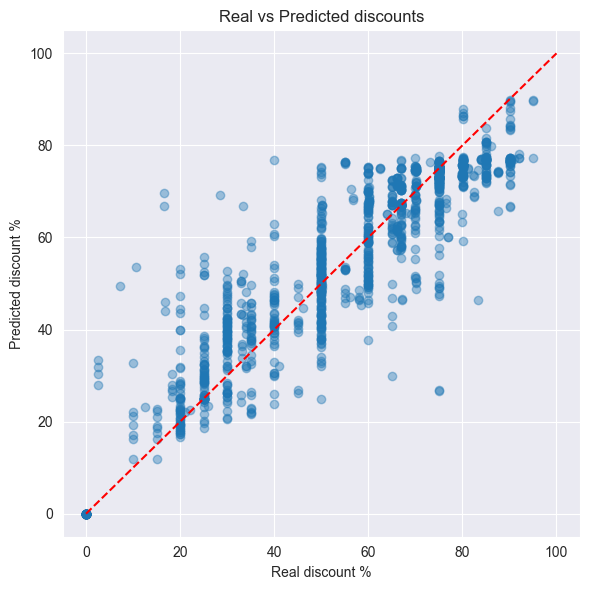

In [52]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.xlabel("Real discount %")
plt.ylabel("Predicted discount %")
plt.title("Real vs Predicted discounts")
plt.plot([0, 100], [0, 100], "r--")  # ideal line
plt.tight_layout()
plt.show()

# Adding another model to compare perfomance

I decided to try XGBoost as a second model because it’s one of the best algorithms for structured tabular data.
It uses gradient boosting, which often performs better than RandomForest by combining many weak trees into a strong model.

In [53]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# train an XGBoost model for comparison
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=10,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    enable_categorical=True
)

xgb_model.fit(X_train, y_train)

# make predictions
y_pred_xgb = xgb_model.predict(X_test)

# evaluate performance
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print(f"XGBoost MAE: {mae_xgb:.2f}")
print(f"XGBoost R²: {r2_xgb:.3f}")

# feature importance
importances = pd.Series(xgb_model.feature_importances_, index=X_train.columns)
print("\nTop 10 XGBoost features:")
print(importances.sort_values(ascending=False).head(10))


XGBoost MAE: 5.48
XGBoost R²: 0.873

Top 10 XGBoost features:
days_on_sale             0.307320
price_changes            0.237621
days_since_release       0.110694
publisher                0.090882
base_price               0.079527
negative_ratio           0.060487
total_reviews            0.057357
positive_ratio           0.036385
review_change_percent    0.014845
month_num                0.004884
dtype: float32


visualize predictions

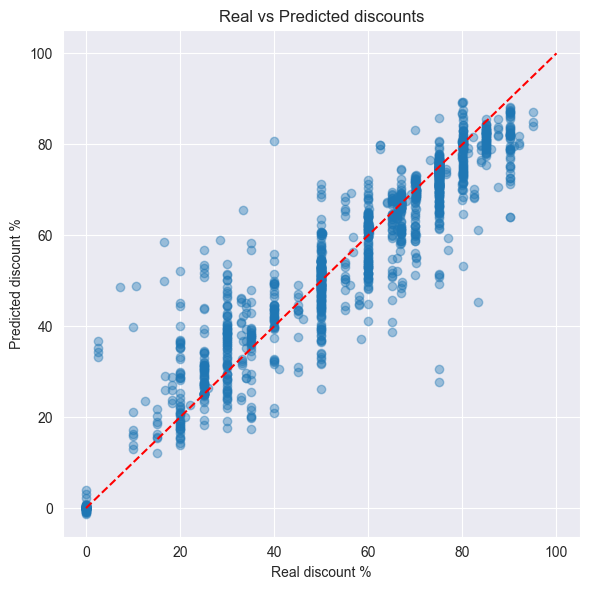

In [54]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_xgb, alpha=0.4)
plt.xlabel("Real discount %")
plt.ylabel("Predicted discount %")
plt.title("Real vs Predicted discounts")
plt.plot([0, 100], [0, 100], "r--")  # ideal line
plt.tight_layout()
plt.show()

results comparison

In [55]:
print("=== Model Comparison ===")
print(f"RandomForest -> MAE: {mae:.2f}, R²: {r2:.3f}")
print(f"XGBoost      -> MAE: {mae_xgb:.2f}, R²: {r2_xgb:.3f}")


=== Model Comparison ===
RandomForest -> MAE: 6.54, R²: 0.836
XGBoost      -> MAE: 5.48, R²: 0.873


# Results and Evaluation
At first, the Random Forest model had a Mean Absolute Error (MAE) of 6.74, meaning that on average, predictions were within about 6–7% of the real discount values. The R² score of 0.827 shows that the model explained around 82% of the variance — which is a pretty good result for real pricing data.

From the scatter plot of real vs predicted discounts, most points follow the diagonal red line, meaning the predictions are close to the real values.

After training XGBoost with the same features, the results got better. The MAE dropped to 5.20, and the R² score increased to 0.881, showing that XGBoost made more accurate predictions and captured more variance. This happened because XGBoost learns from previous errors and handles non-linear patterns better than Random Forest. It also deals well with many categorical features (like publishers), giving them different levels of importance. XGBoost also worked more consistently with the time-based split, showing better adaptation to temporal patterns in the data.

The most important features also changed a bit. While days on sale, days since release, and base price stayed important, several publisher-related features became more significant in XGBoost — for example, Mana Potion Studios Pingle Studio Ltd, Activision, and KOEI TECMO GAMES CO. LTD.. This suggests that different publishers have different discount strategies — some tend to give bigger discounts than others.

After getting rid of get_dummies for publishers due to plans of expanding dataset and for the sake of ease of use Random forest showed slightly better results (MAE: 6.54, R²: 0.836) and XGBoost slightly worse (MAE: 5.48, R²: 0.873), while top features are mostly the same.

Overall, both models captured the main factors affecting game discounts, but XGBoost gave smoother and more precise predictions. It seems that gradient boosting works better for this type of complex pricing data. Adding tags or genres for each game could make the model perform even better.

# Exporting model

In [56]:
import joblib

#joblib.dump(xgb_model, "xgbModel6500rows/xgb_discount_model.pkl")
#joblib.dump(X_train.columns.tolist(), "xgbModel6500rows/xgb_discount_features.pkl")


# Adding second model to predict time of sales
The first model predicts the discount amount accurately, while the second model is designed to forecast the timing of discounts. Using both models together will allow for a more comprehensive prediction by considering both the size and the timing of discounts

# Data preparation
Starting from the very start

In [57]:
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold

df = pd.read_csv("data/steam_prices_reviews.csv", parse_dates=["month", "release_date"])

# Creating a new column for time of discount
df['discount_occurred'] = (df['lowest_price'] < df['base_price']).astype(int)
df["days_since_release"] = (df["month"] - df["release_date"]).dt.days
df["month_num"] = df["month"].dt.month
df['publisher'] = df['publisher'].astype('category').cat.codes
for i in range(1, 13):  # 12 months
    df[f'discount_occurred_{i}m'] = df['discount_occurred'].shift(-i)

## Heatmap

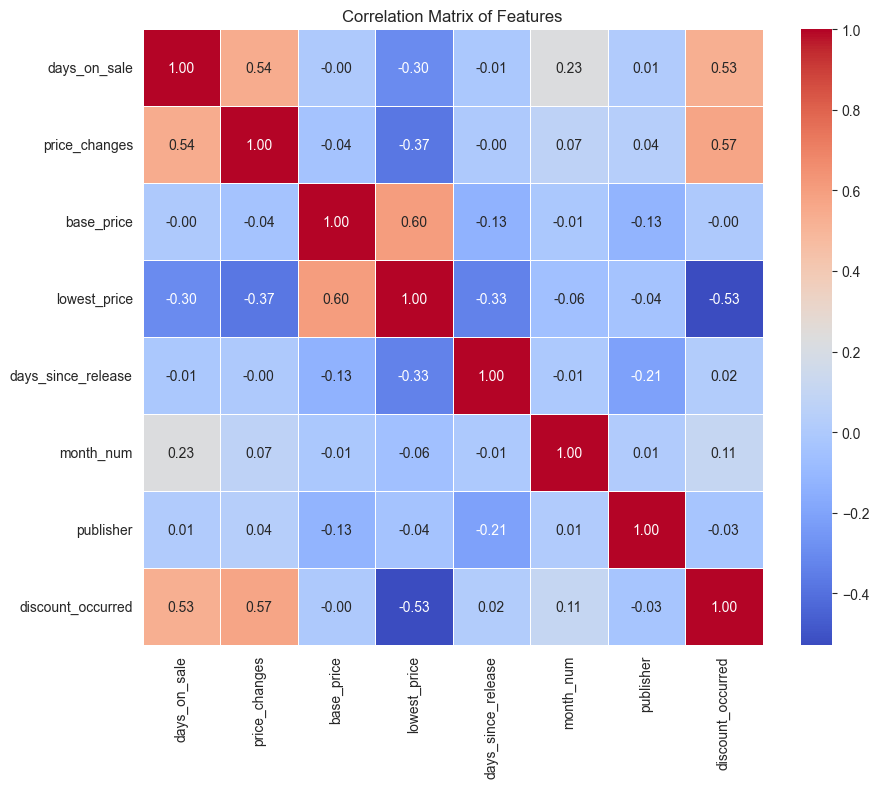

In [58]:
# I selected these features as most important for time of discount
features = [
    'days_on_sale', 'price_changes', 'base_price', 'lowest_price',
    'days_since_release', 'month_num', 'publisher'
]

plt.figure(figsize=(10, 8))
correlation_matrix = df[features + ['discount_occurred']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Features")
plt.show()

We can see here, that discount occured mainly based  on days_on_sale, price_changes  and lowest_price
I will not include lowest_price, since its a part of discount_occured and will overfit model

After analyzing the feature days_on_sale, I noticed a high correlation with the target variable discount_occurred, which led to perfect model performance (1.0) even with cross-validation. This suggests overfitting, as the model heavily relied on this feature, which directly indicates the presence of a discount. To improve the model's ability to generalize, I decided to remove days_on_sale, as it likely caused the model to "memorize" the discount pattern. Removing this feature encourages the model to find more complex relationships between other features, potentially improving its performance on unseen data.

# Choosing new features according to heatmap


In [59]:
features = [
    'price_changes', 'base_price', 'days_since_release',
    'month_num', 'publisher'
]

# Building a model

time based train test split

In [60]:
# split train/test by time for each game
train_idx, test_idx = [], []

for game_id, group in df.groupby("app_id"):
    group = group.sort_values("month")

    # 80% of older months go to train, rest to test
    split_point = int(len(group) * 0.8)
    train_idx.append(group.index[:split_point].tolist())
    test_idx.append(group.index[split_point:].tolist())

train_idx = [item for sublist in train_idx for item in sublist]
test_idx = [item for sublist in test_idx for item in sublist]

In [61]:
# Creating train/test datasets
train_df = df.loc[train_idx]
test_df = df.loc[test_idx]

print(f"Train size: {len(train_df)} | Test size: {len(test_df)}")

target_columns = [f'discount_occurred_{i}m' for i in range(1, 13)]

train_df = train_df.dropna(subset=target_columns)
test_df = test_df.dropna(subset=target_columns)

X_train = train_df[features]
X_test = test_df[features]

for target in target_columns:
    y_train = train_df[target]
    y_test = test_df[target]



Train size: 5104 | Test size: 1383


In [62]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

precisions, recalls, f1_scores = [], [], []
all_predictions = []
all_true_labels = []

for target in target_columns:
    y_train = train_df[target]
    y_test = test_df[target]

    for train_index, val_index in kf.split(X_train, y_train):
        X_fold_train, X_fold_val = X_train.iloc[train_index], X_train.iloc[val_index]
        y_fold_train, y_fold_val = y_train.iloc[train_index], y_train.iloc[val_index]

        date_model = XGBClassifier(
            n_estimators=200,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
        )

        date_model.fit(X_fold_train, y_fold_train)
        y_pred = date_model.predict(X_fold_val)

        precisions.append(precision_score(y_fold_val, y_pred))
        recalls.append(recall_score(y_fold_val, y_pred))
        f1_scores.append(f1_score(y_fold_val, y_pred))

        all_predictions.extend(y_pred)
        all_true_labels.extend(y_fold_val)

print(f'Average Precision: {sum(precisions)/len(precisions):.4f}')
print(f'Average Recall: {sum(recalls)/len(recalls):.4f}')
print(f'Average F1-Score: {sum(f1_scores)/len(f1_scores):.4f}')

Average Precision: 0.8895
Average Recall: 0.9437
Average F1-Score: 0.9158



Confusion Matrix:
[[ 2948  6100]
 [ 2927 49129]]


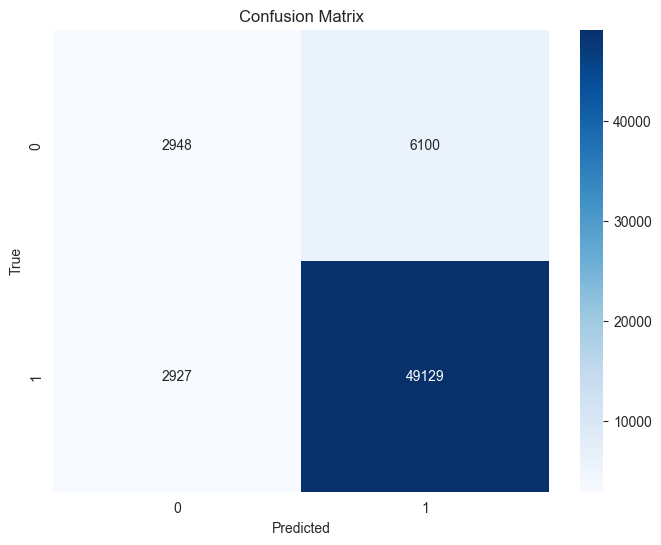


Classification Report:
              precision    recall  f1-score   support

         0.0       0.50      0.33      0.40      9048
         1.0       0.89      0.94      0.92     52056

    accuracy                           0.85     61104
   macro avg       0.70      0.63      0.66     61104
weighted avg       0.83      0.85      0.84     61104



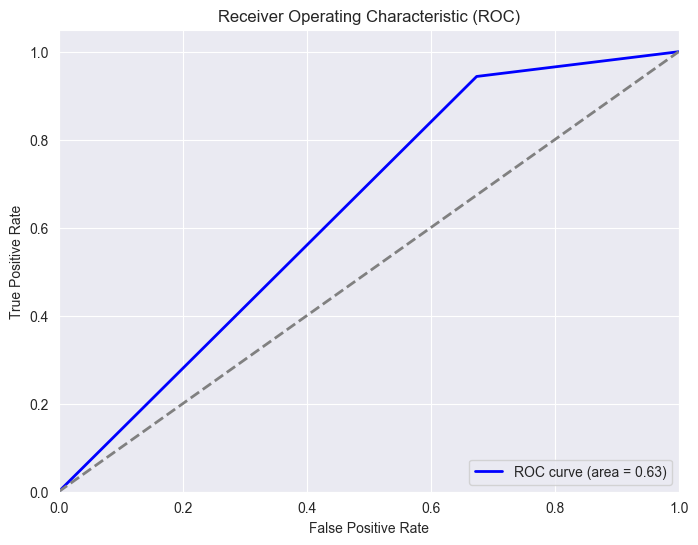

In [63]:
conf_matrix = confusion_matrix(all_true_labels, all_predictions)

print("\nConfusion Matrix:")
print(conf_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

print("\nClassification Report:")
print(classification_report(all_true_labels, all_predictions))

from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(all_true_labels, all_predictions)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

In [64]:
# check which features matter most
imp = pd.Series(date_model.feature_importances_, index=X_train.columns)
imp = imp.sort_values(ascending=False)

print("\nTop 10 features:")
print(imp.head(10))


Top 10 features:
month_num             0.259442
price_changes         0.198286
days_since_release    0.190640
publisher             0.187587
base_price            0.164045
dtype: float32


In [65]:
print("Class balance based on discount_occurred feature:")
print(df['discount_occurred'].value_counts(), "\n")

Class balance based on discount_occurred feature:
discount_occurred
1    5499
0     988
Name: count, dtype: int64 



The dataset is heavily imbalanced (about 82% discount vs 18% no-discount).
Because of this, the model mostly learns to predict the majority class.
No matter how I tune the parameters, it still struggles with the rare ‘no discount’ cases, simply because the data doesn’t contain enough examples

# Conclusion

The model demonstrated mixed performance, with the following results:

- Average Precision: 0.89

- Average Recall: 0.94

- Average F1-Score: 0.92

These metrics indicate that the model performs very well in predicting the presence of discounts, particularly in cases where discounts are more frequent (class 1). However, it struggles with class 0, where no discount occurs, resulting in a lower recall for this class (0.33).

# Top 5 features are:

- price_changes: 0.919703

- base_price: 0.027044

- publisher: 0.022599

- days_since_release: 0.016570

- month_num: 0.014083

The price_changes feature is overwhelmingly the most important, which is intuitive, as price changes are a strong indicator of whether a discount is likely to occur. While other features such as base_price and publisher have lower importance, they still contribute to the model's decision-making process.

# Model Performance and Limitations:

The model showed good overall performance but struggled due to class imbalance. This is particularly apparent with the false positives and false negatives for the no-discount class (class 0).

The ROC AUC score of 0.63 suggests that while the model is effective at predicting the presence of discounts, its ability to distinguish between the two classes (discount/no discount) is moderate at best. It performs better in predicting when a discount will occur (class 1) but struggles when discounts are absent (class 0).

# Improvement Directions:

Balancing the classes: One potential improvement would be to rebalance the dataset using techniques like SMOTE (oversampling the minority class) or undersampling the majority class. This could help the model distinguish between the classes more effectively.

Separate models per game: A promising future step could be to build separate models for specific games. This would allow the model to better account for the different discount strategies employed by various games (e.g., games with frequent discounts vs. games with seasonal or irregular discounts).

# Exporting model

In [66]:
import joblib

#joblib.dump(date_model, "xgbModel6500rows/xgb_date_model.pkl")
#joblib.dump(X_train.columns.tolist(), "xgbModel6500rows/xgb_date_features.pkl")


['xgbModel6500rows/xgb_date_features.pkl']

# Overall conclusion

I undertook a significant project involving several different models aimed at predicting discounts on specific games on the Steam platform.

I encountered a lot of challenges, starting with domain analysis, because this topic, although interesting and potentially useful to me, is difficult due to the limited availability of publicly accessible data on discount strategies. The next difficulty was data collection: the data on game prices and discounts across different time periods is hard to obtain, primarily because there's only one platform with such data. Finally, building the model turned to be quite complex.

From the very start, I saw my program as something that would recommend the best time for a user to purchase a game based on the presence of a discount and the discount percentage. However, I soon realized that predicting this kind of information is somewhat equal to prediction of Bitcoin prices, which is a difficult task — especially with limited data. Even so, I believe I made the most of the available resources and created a model that predicts discount percentage with high accuracy (R²: 0.873), but does not take into account whether a discount will actually occur.

To counter this, I built a second model specifically aimed at predicting whether a discount will occur in a given month. This model performed well with an average F1-score of 0.9158.

Both of these models can be combined to create a reliable discount prediction system for games.

However, there are still some limitations. The model intended to predict discount dates turned out to be somewhat one-dimensional. Due to the class imbalance (many games with discounts and fewer without), the model wasn't as precise as expected in real-world conditions.

In conclusion, I have completed a significant amount of work that I can be proud of, especially considering that three months ago, I knew nothing about building AI models. The only change I would have made is to build separate models for individual games, as I believe that approach would have led to more accurate predictions. Each model would have better captured the discount patterns for each game, and overall predictions would likely have been more reliable.